# Presión fiscal y crecimiento del PIB por habitante

In [ ]:
# Parámetros de la gráfica
SLUG = "economia"  # carpeta en research/temas/
GRAFICA_ID = "presion-fiscal-crecimiento"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Presión fiscal y crecimiento del PIB por habitante"  # `titulo` de la gráfica en config.json
DESDE = 1976  # primer año candidato (METODOLOGIA §2.3)
UNIVERSO = "ocde"  # ocde | ue27: todos sus países con dato en los dos ejes (METODOLOGIA §2.6)
EJE_X = {"titulo": "Presión fiscal, media del periodo", "unidad": "% del PIB (media del periodo)"}
EJE_Y = {"titulo": "Crecimiento medio anual del PIB por habitante", "unidad": "% de crecimiento medio anual"}
ANIOS = None  # (desde, hasta) si el config fija una ventana; None = último año común de cada país
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

Cada punto es un país de la OCDE con dato en los diez años del periodo.

- **Eje horizontal:** la **media de la presión fiscal** (impuestos y cotizaciones sociales en porcentaje del PIB, el mismo indicador que la gráfica `presion-fiscal` de Fiscalidad) durante los diez últimos años en que la OCDE publica su media.
- **Eje vertical:** el **crecimiento medio anual del PIB por habitante**, descontada la inflación, entre el primer y el último año de ese mismo periodo (tasa anual compuesta; el mismo PIB real por habitante que la gráfica `pib-per-capita`).

**Para qué sirve.** Pone junto a los impuestos el crecimiento de la economía: es la comparación que invocan quienes sostienen que una presión fiscal alta frena el crecimiento. Quienes la defienden sostienen que lo que se financia con impuestos (educación, infraestructuras, sanidad) lo sostiene a largo plazo, algo que un periodo de diez años no recoge del todo. Se usa el crecimiento y no el nivel del PIB por habitante porque el nivel mezcla las dos direcciones (los países más ricos tienden a recaudar más; la comparación de niveles está en `presion-fiscal-pib-per-capita` de Fiscalidad). **La relación entre dos indicadores no muestra que uno cause el otro**: no se dibuja línea de tendencia ni se calcula la correlación.

**Limitaciones.**
- El crecimiento es muy sensible al ciclo económico: por eso se toma una media de varios años y el mismo periodo para todos los países.
- Los países con menos renta al inicio del periodo tienden a crecer más (convergencia), con independencia de sus impuestos.
- El PIB de Irlanda y de Luxemburgo está muy influido por las multinacionales y los trabajadores no residentes.
- El periodo incluye la pandemia de 2020 y 2021.

## 2. Descarga

- **OCDE, Revenue Statistics** (`OECD.CTP.TPS,DSD_REV_COMP_OECD@DF_RSOECD`, versión 2.0): ingresos fiscales totales (`TAX_REV`, `S13`, `_T`) en % del PIB de los 38 países de la OCDE, y la media simple que publica (`OECD_REP`), que fija el último año del periodo.
- **OCDE, National Accounts at a Glance** (`OECD.SDD.NAD,DSD_NAAG@DF_NAAG_I`, versión 1.0): PIB real por habitante (`B1GQ_R_POP`) en dólares PPA a precios constantes (`USD_PPP_PS`), volúmenes encadenados.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.paises import paises_de
from lib.writer import construir_dispersion_data, write_dispersion_data

PAISES = paises_de(UNIVERSO)

from datetime import date

from lib import eurostat, oecd
from lib.paises import nombre_punto
from lib.tipos import FuenteMeta

AREAS = {c: c for c in PAISES}  # todos los países del universo, con su código como clave de serie
HOY = date.today().isoformat()

# Presión fiscal (OCDE, Revenue Statistics): la misma que fiscalidad/presion-fiscal
DATAFLOW_REV = "OECD.CTP.TPS,DSD_REV_COMP_OECD@DF_RSOECD,2.0"
CLAVE_REV = "{AREA}.TAX_REV.S13._T._T.PT_B1GQ.A"
DATAFLOW_PIB = "OECD.SDD.NAD,DSD_NAAG@DF_NAAG_I,1.0"
CLAVE_PIB = "A.{AREA}.B1GQ_R_POP.USD_PPP_PS.NAAG_I"
N_ANIOS = 10  # años del periodo (indicación humana del 2026-10-22)

x_anual, _ = oecd.get(DATAFLOW_REV, CLAVE_REV, areas=AREAS, desde=DESDE)
y_anual, _ = oecd.get(DATAFLOW_PIB, CLAVE_PIB, areas=AREAS, desde=DESDE)
media_x, _ = oecd.get(DATAFLOW_REV, CLAVE_REV, areas={"OECD_REP": "OECD_REP", "OECD": "OECD"}, desde=DESDE)
media_y, _ = oecd.get(DATAFLOW_PIB, CLAVE_PIB, areas={"OECD": "OECD"}, desde=DESDE)
print("Medias de la presión fiscal:", sorted(media_x["serie"].unique()), "· del PIB por habitante:", sorted(media_y["serie"].unique()))

Medias de la presión fiscal: ['OECD_REP'] · del PIB por habitante: ['OECD']


## 3. Transformación

1. **Periodo:** los diez últimos años en que Revenue Statistics publica la media de la OCDE (`OECD_REP`), el mismo para todos los países.
2. **Eje x:** media de la presión fiscal de esos diez años. **Eje y:** tasa anual compuesta del PIB real por habitante entre el primer y el último año del periodo: `(valor del último año / valor del primer año)^(1 / años entre ambos) − 1`.
3. Los países sin los diez años en los dos ejes quedan fuera y se listan en las notas.
4. El campo `anio` de cada punto es el último año del periodo y el título de cada eje indica el periodo.
5. **Sin punto de la media OCDE:** cada fuente publica una media distinta (media simple de los países en Revenue Statistics; agregado ponderado en las cuentas nacionales).

In [ ]:
def unir(xs):
    xs = [str(x) for x in xs]
    return xs[0] if len(xs) == 1 else f"{', '.join(xs[:-1])} y {xs[-1]}"


def es(v, d=1):
    return estilos.formato_es(v, d)


assert not (set(media_x["serie"]) & set(media_y["serie"])), "Las dos fuentes publican la misma media: revisar si se añade el punto"

# 1. Periodo de diez años que termina en el último año de la media OCDE de Revenue Statistics
ultimo = int(media_x[media_x["serie"] == "OECD_REP"]["periodo"].max())
anios = list(range(ultimo - N_ANIOS + 1, ultimo + 1))
primero = anios[0]
PERIODO = f"{primero}-{ultimo}"
print("Periodo:", PERIODO)


def completos(df):
    """Países con dato en todos los años del periodo."""
    d = df[df["periodo"].isin(anios)].pivot(index="serie", columns="periodo", values="valor")
    return d.dropna(how="any").reindex(columns=anios).dropna()


px, py = completos(x_anual), completos(y_anual)
paises = sorted(set(px.index) & set(py.index))
sin_dato_periodo = sorted(set(PAISES) - set(paises))

x = pd.DataFrame({"serie": paises, "periodo": ultimo, "valor": px.loc[paises].mean(axis=1).values})
crec = ((py.loc[paises, ultimo] / py.loc[paises, primero]) ** (1 / (ultimo - primero)) - 1) * 100
y = pd.DataFrame({"serie": paises, "periodo": ultimo, "valor": crec.values})
EJE_X = {"titulo": f"Presión fiscal, media {PERIODO}", "unidad": "% del PIB (media del periodo)"}
EJE_Y = {"titulo": f"Crecimiento medio anual del PIB por habitante, {PERIODO}", "unidad": "% de crecimiento medio anual"}

_, FLUJO_REV, VERSION_REV = DATAFLOW_REV.split(",")
_, FLUJO_PIB, VERSION_PIB = DATAFLOW_PIB.split(",")
fuentes = [
    FuenteMeta("eje_x", oecd.ORGANISMO, f"{FLUJO_REV} (Revenue Statistics, versión {VERSION_REV}): TAX_REV, S13, _T (TOTALTAX), PT_B1GQ", oecd.URL_EXPLORER, HOY),
    FuenteMeta("eje_y", oecd.ORGANISMO, f"{FLUJO_PIB} (National Accounts at a Glance, versión {VERSION_PIB}): B1GQ_R_POP, USD_PPP_PS", oecd.URL_EXPLORER, HOY),
]
NOTAS = [
    f"Periodo: {PERIODO}, los diez últimos años en que Revenue Statistics publica la media de la OCDE; el mismo para "
    "todos los países. El año de cada punto es el último del periodo.",
    f"Presión fiscal: OCDE, Revenue Statistics ({FLUJO_REV}, versión {VERSION_REV}): impuestos y cotizaciones sociales "
    f"obligatorias de las administraciones públicas, en porcentaje del PIB; media de los diez años {PERIODO}.",
    f"Crecimiento: tasa anual compuesta del PIB real por habitante entre {primero} y {ultimo} (OCDE, National Accounts "
    f"at a Glance, {FLUJO_PIB}, versión {VERSION_PIB}: dólares PPA a precios constantes, volúmenes encadenados). "
    f"Compara el último año con el primero del periodo, así que solo depende de esos dos años.",
    "Los países con menos renta al inicio del periodo tienden a crecer más (convergencia), con independencia de sus impuestos.",
    "El PIB de Irlanda y de Luxemburgo está muy influido por las multinacionales y por los trabajadores no residentes.",
    "Sin punto de la media OCDE ni de la UE-27: Revenue Statistics publica la media simple de los países y las cuentas "
    "nacionales el agregado ponderado, que no son el mismo concepto, y la OCDE no publica el agregado de la UE-27 en las cuentas.",
]
if {primero, ultimo} & {2020, 2021}:
    NOTAS.append(
        "El primer o el último año del periodo es de la pandemia (2020 o 2021), por lo que la tasa compuesta recoge "
        "la caída o el rebote de esos años."
    )
else:
    NOTAS.append(
        f"El periodo incluye la pandemia de 2020 y 2021; el crecimiento compara {ultimo} con {primero}, años que no son de la "
        "caída ni del rebote, y por eso las tasas reflejan el balance de todo el periodo."
    )
if sin_dato_periodo:
    NOTAS.append(
        f"Sin los diez años del periodo en los dos ejes ({len(sin_dato_periodo)} de los {len(PAISES)} países): "
        f"{unir(sorted(nombre_punto(c) for c in sin_dato_periodo))}."
    )

Periodo: 2015-2024


## 4. Visualización

Un punto por país, sin línea de tendencia ni correlación (METODOLOGIA §2.6).

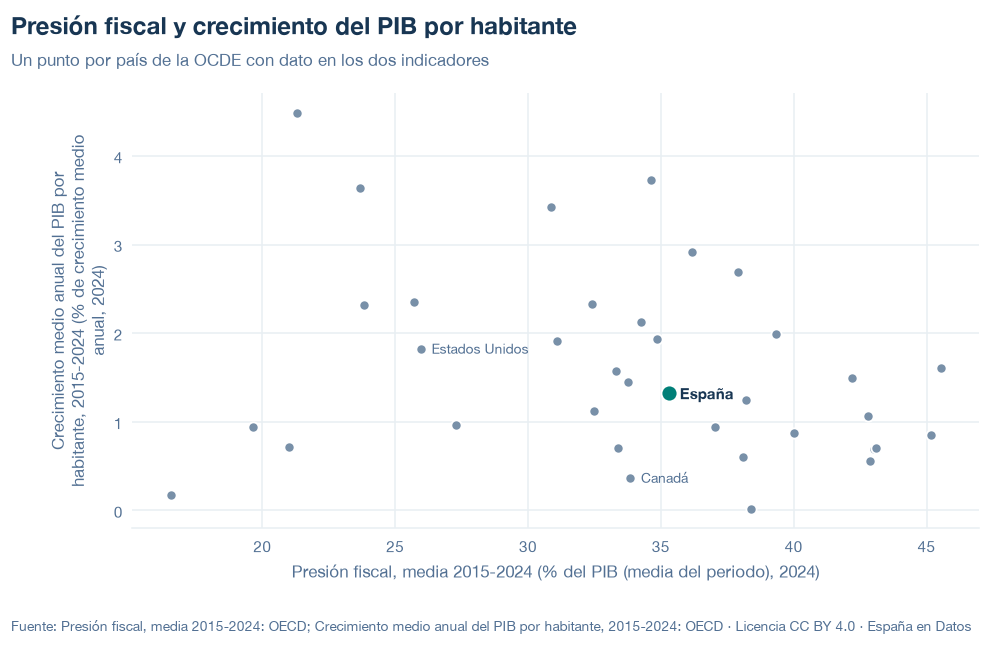

codigo  anio         x        y
   AUT  2024 42.862060 0.556305
   BEL  2024 42.801356 1.061812
   CAN  2024 33.850120 0.368463
   CHE  2024 27.303409 0.968969
   CHL  2024 20.986285 0.713932
   COL  2024 19.646478 0.944206
   CRI  2024 23.835145 2.321924
   CZE  2024 33.750265 1.448327
   DEU  2024 38.104918 0.601518
   DNK  2024 45.526391 1.610642
   ESP  2024 35.310948 1.320536
   EST  2024 33.315976 1.577367
   FIN  2024 43.030664 0.695973
   FRA  2024 45.151537 0.851408
   GBR  2024 33.397735 0.701018
   GRC  2024 39.323657 1.989237
   HUN  2024 36.189082 2.915764
   IRL  2024 21.307036 4.488682
   ISL  2024 37.039196 0.945140
   ISR  2024 31.101481 1.916108
   ITA  2024 42.210511 1.496985
   KOR  2024 25.706235 2.346515
   LTU  2024 30.870231 3.418934
   LUX  2024 38.383464 0.020345
   LVA  2024 32.394411 2.333546
   MEX  2024 16.541107 0.171817
   NLD  2024 38.211536 1.241324
   NOR  2024 40.002247 0.874246
   NZL  2024 32.497177 1.118267
   POL  2024 34.626958 3.730659
   PRT  

In [ ]:
datos = construir_dispersion_data(
    x, y, fuentes, id=GRAFICA_ID, universo=UNIVERSO, eje_x=EJE_X, eje_y=EJE_Y, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, anios=ANIOS,
)
fig = estilos.figura(datos, titulo=TITULO)
estilos.mostrar(fig)
print(pd.DataFrame(datos["puntos"]).to_string(index=False))

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web (`codigo;pais;anio;eje_x;eje_y`).

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_dispersion_data(
    x, y, fuentes, id=GRAFICA_ID, universo=UNIVERSO, eje_x=EJE_X, eje_y=EJE_Y, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, anios=ANIOS,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/presion-fiscal-crecimiento.json y data/presion-fiscal-crecimiento.csv


## 6. Fuentes, notas y licencia

- OCDE, Revenue Statistics: `OECD.CTP.TPS,DSD_REV_COMP_OECD@DF_RSOECD,2.0` (`TAX_REV`, `S13`, `_T`, `PT_B1GQ`).
- OCDE, National Accounts at a Glance: `OECD.SDD.NAD,DSD_NAAG@DF_NAAG_I,1.0` (`B1GQ_R_POP`, `USD_PPP_PS`).

La fecha de consulta de cada eje está en `fuentes` del JSON; las notas incluyen los países sin dato y la advertencia de que la relación no muestra causa.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.